# Лабораторна робота № 5
## Географічні дані OpenStreetMap: від тегів до маршруту

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви — аналітик у туристичному застосунку. Завдання: для заданого міста
**відібрати десять найвартісніших історико-культурних об'єктів** і
**спланувати піший маршрут**, який починається на залізничному вокзалі,
обходить усі десять і повертається на вокзал.

Слово «найвартісніші» в даних не записане. Критерій ви побудуєте самі —
і захистите його.

Потім те саме для **тридцяти** об'єктів. Результат цієї, більшої задачі
стане базою порівняння в **лабораторній роботі № 8**, де ту саму задачу
розв'язуватимуть генетичним та мурашиним алгоритмами.

### Що здаєте

1. Цей ноутбук із виконаними комірками (усі виводи збережені).
2. Файл `lr5_результати.json` — результати для ЛР8.
3. Карту `lr5_маршрут.html`.
4. Звіт у кінці ноутбука: відповіді на сім питань.

### Що оцінюється

| критерій | 0 | 2 | 3 | 4 |
|---|---|---|---|---|
| Відбір об'єктів | теги взято навмання | фільтр працює | фільтр обґрунтовано | показано, що відкинуто і чому |
| Критерій рейтингу | немає | є формула | ваги пояснено | порівняно з альтернативним критерієм |
| Маршрут | не будується | будується | перевірено коректність | пояснено різницю методів числом |
| Карта | немає | точки на карті | маршрут по ребрах графа | видно різницю з прямими відрізками |
| Звіт | немає | формально | з числами | з висновком, якого не було в завданні |

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Місто підтягнеться само.

In [1]:
STUDENT_NAME = 'Недосіка Назарій'
LIST_NUMBER  = 14

CITIES = [
    'Львів', 'Київ', 'Харків', 'Одеса', 'Дніпро',
    'Чернівці', 'Івано-Франківськ', 'Тернопіль', 'Ужгород', 'Луцьк',
    'Рівне', 'Хмельницький', 'Вінниця', 'Житомир', 'Чернігів',
    'Черкаси', 'Полтава', 'Суми', 'Кропивницький', 'Запоріжжя',
    'Миколаїв', 'Кривий Ріг', 'Кам\u2019янець-Подільський', 'Мукачево',
    'Коломия', 'Дрогобич', 'Біла Церква', 'Ніжин', 'Остріг', 'Умань',
]

assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
CITY = CITIES[(LIST_NUMBER - 1) % len(CITIES)] + ', Україна'
print('варіант %d: %s' % (LIST_NUMBER, CITY))

варіант 14: Житомир, Україна


> Якщо викладач призначив вам інше місто — просто перепишіть `CITY` вручну
> і зазначте це у звіті.

In [2]:
import importlib.util, subprocess, sys
REQUIRED = ['osmnx', 'geopandas', 'shapely', 'pyproj', 'pyarrow',
            'folium', 'mapclassify', 'h3', 'networkx']
missing = [p for p in REQUIRED if importlib.util.find_spec(p) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

усі пакети на місці


In [3]:
import warnings; warnings.filterwarnings('ignore')
import json, time, os, collections
import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx
import matplotlib.pyplot as plt
import folium
from xyzservices import providers as xyz

BASEMAP = xyz.Esri.WorldGrayCanvas   # CARTO з 2026 р. вимагає ключ API
pd.set_option('display.width', 200)
print('geopandas', gpd.__version__)

geopandas 1.2.0


---
## 1. Два способи дістати дані

Робоча програма вимагає порівняти два способи доступу **за обсягом переданих
даних і за часом**:

* **живий запит** — `osmnx` питає Overpass API просто зараз;
* **знімок** — ті самі дані, збережені у файли GeoParquet, читаються з диска.

Нижче — живий запит. Запустіть його **один раз**: він збереже теку зі знімком,
і всі наступні запуски читатимуть з неї.

> Overpass — безкоштовний сервіс і обмежує частоту. Якщо запит не пройшов —
> зачекайте хвилину й повторіть. Якщо не проходить взагалі, візьміть
> резервний знімок у викладача і вкажіть це у звіті.

In [4]:
import osmnx as ox

OUT = 'osm_' + CITY.split(',')[0].strip().lower().replace(' ', '_')
os.makedirs(OUT, exist_ok=True)
ox.settings.use_cache = True
ox.settings.cache_folder = os.path.join(OUT, 'cache')
ox.settings.requests_timeout = 300
ox.settings.overpass_rate_limit = True

TOURISM_OK = ['museum', 'attraction', 'gallery', 'artwork', 'viewpoint']

def cache_bytes():
    import pathlib
    p = pathlib.Path(ox.settings.cache_folder)
    return sum(f.stat().st_size for f in p.glob('*.json')) if p.exists() else 0

print('тека знімка:', OUT)

тека знімка: osm_житомир


### Дві налаштовані дрібниці, без яких запит не пройде

Це не формальності — кожна з них ламає збір по-своєму, і жодна не схожа
на свою справжню причину.

**Представитись.** Overpass відповідає **HTTP 406** клієнтові, який прийшов
із типовим заголовком `python-requests`. `osmnx` надсилає свій `User-Agent`
сам, але якщо ви звертаєтесь до сервісу напряму — надсилайте теж.
Рядок має бути **лише латиницею**: HTTP-заголовки передаються в latin-1,
і кирилиця кладе запит помилкою `UnicodeEncodeError` ще до відправлення.

**Обрати машину.** За іменем `overpass-api.de` стоїть кілька серверів, і
частина з них відмовляє у з’єднанні. `osmnx` закріплює одну адресу на
всю сесію — навмисно, щоб не порушувати облік слотів. Якщо закріпиться та,
що відмовляє, впаде весь збір. Тому адресу обираємо самі, вже перевірену.

In [5]:
import socket

USER_AGENT = ('LvivPolytechnic-SK26-coursework/1.0 '
              '(https://lpnu.ua; student lab assignment)')
assert USER_AGENT.isascii(), 'HTTP-заголовки — latin-1, кирилиця тут не працює'
ox.settings.http_user_agent = USER_AGENT


def pin_working_ip(hostname, port=443, timeout=8):
    """Закріпити для цього імені адресу, яка справді відповідає."""
    try:
        infos = socket.getaddrinfo(hostname, port, socket.AF_INET, socket.SOCK_STREAM)
    except Exception as e:
        print('не вдалось резолвити %s: %s' % (hostname, type(e).__name__))
        return None
    ips = sorted({i[4][0] for i in infos})
    good = []
    for ip in ips:
        s = socket.socket(); s.settimeout(timeout)
        try:
            s.connect((ip, port)); good.append(ip)
        except Exception:
            pass
        finally:
            s.close()
    print('%s: машин %d, відповідають %d %s' % (hostname, len(ips), len(good), good))
    if not good:
        return None
    original = socket.gethostbyname
    socket.gethostbyname = lambda h: good[0] if h == hostname else original(h)
    print('закріплено', good[0])
    return good[0]


pin_working_ip('overpass-api.de')

overpass-api.de: машин 2, відповідають 2 ['162.55.144.139', '65.109.112.52']
закріплено 162.55.144.139


'162.55.144.139'

> Якщо жодна машина не відповіла — виконайте комірку ще раз за хвилину,
> або візьміть у викладача резервний знімок і зазначте це у звіті.
> Інші дзеркала перелічені на сторінці
> [Overpass API](https://wiki.openstreetmap.org/wiki/Overpass_API);
> адресу можна підставити у `ox.settings.overpass_url`.

### Завдання 1.1

Допишіть функцію `fetch`: вона має зберегти шар у `.parquet`, а якщо файл
уже є — прочитати його, **не звертаючись до мережі**. Поверніть також,
скільки МБ пішло мережею і скільки секунд це зайняло.

Підказка щодо `clean`: у OSM одна колонка може містити і число, і список
(ребро, склеєне з кількох шляхів). Parquet вимагає один тип на колонку,
тому неоднорідну колонку треба звести до тексту **цілком**.

In [6]:
def clean(gdf):
    g = gdf.reset_index()
    for c in g.columns:
        if c == 'geometry':
            continue
        boxed = g[c].map(lambda v: isinstance(v, (list, dict, set, tuple))).any()
        if boxed or g[c].dtype == object:
            g[c] = g[c].map(
                lambda v: None if v is None or (isinstance(v, float) and pd.isna(v))
                else (json.dumps(v, ensure_ascii=False)
                      if isinstance(v, (list, dict, set, tuple)) else str(v))
            ).astype('string')
    return g


COST = {}

def fetch(name, getter):
    """Повертає шар. Якщо файл уже збережено — читає з диска."""
    path = os.path.join(OUT, name + '.parquet')
    if os.path.exists(path) and os.path.getsize(path) > 0:
        t0 = time.time()
        g = gpd.read_parquet(path)
        COST[name] = {'спосіб': 'знімок', 'записів': len(g),
                      'передано_МБ': 0.0,
                      'файл_МБ': round(os.path.getsize(path) / 1e6, 3),
                      'секунд': round(time.time() - t0, 3)}
        return g

    t0, b0 = time.time(), cache_bytes()
    g = clean(getter())
    g.to_parquet(path, index=False)
    g = gpd.read_parquet(path)
    COST[name] = {'спосіб': 'живий запит', 'записів': len(g),
                  'передано_МБ': round((cache_bytes() - b0) / 1e6, 3),
                  'файл_МБ': round(os.path.getsize(path) / 1e6, 3),
                  'секунд': round(time.time() - t0, 1)}
    return g

### Примітка студента: межа міста

Запит `Житомир, Україна` повернув межу всієї області (29825,7 км²), тому межу міста
отримано уточненим запитом. Комірка викладача нижче читає цей збережений файл.

In [7]:
BOUNDARY_P = os.path.join(OUT, 'boundary.parquet')
if not os.path.exists(BOUNDARY_P):
    b = ox.geocode_to_gdf('Zhytomyr, Zhytomyr Oblast, Ukraine')
    area = b.to_crs(32635).area.iloc[0] / 1e6
    assert area < 300, 'отримано не місто: %.1f км²' % area
    clean(b).to_parquet(BOUNDARY_P, index=False)
print('файл межі на місці:', BOUNDARY_P)

файл межі на місці: osm_житомир\boundary.parquet


In [8]:
boundary = fetch('boundary', lambda: ox.geocode_to_gdf(CITY))
poly = boundary.geometry.iloc[0]
print('межа міста отримана, площа %.1f км²'
      % (boundary.to_crs(32635).area.iloc[0] / 1e6))

межа міста отримана, площа 60.4 км²


### Примітка студента: джерело даних

Overpass і два дзеркала не віддали дані: сервер відхилив запит, а дзеркала
повертали таймаут або 502. Тому шари побудовано з файлу Geofabrik для України.
Відношення OSM (об'єкти зі складених частин) при цьому не враховані.
Якщо файли шарів уже є, комірка нічого не завантажує й не перераховує.

In [9]:
LAYERS = ['heritage', 'stations', 'amenities', 'road_nodes', 'road_edges']
AMENITY = ['cafe', 'restaurant', 'drinking_water', 'toilets']

if all(os.path.exists(os.path.join(OUT, n + '.parquet')) for n in LAYERS):
    print('шари вже збережено, побудова не потрібна')
else:
    import re, requests
    if importlib.util.find_spec('osmium') is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'osmium'])
    import osmium

    PBF = 'ukraine-latest.osm.pbf'
    URL = 'https://download.geofabrik.de/europe/ukraine-latest.osm.pbf'
    if not os.path.exists(PBF):
        with requests.get(URL, stream=True, timeout=120) as r:
            r.raise_for_status()
            with open(PBF + '.part', 'wb') as f:
                for chunk in r.iter_content(1024 * 1024):
                    f.write(chunk)
        os.rename(PBF + '.part', PBF)

    W, S, E, N = poly.bounds
    # osmium у Windows не відкриває шлях із кирилицею, тому назви латиницею
    WALK_F, FEAT_F = 'zhytomyr_walk.osm', 'zhytomyr_features.osm'
    BAD_HW = (r'abandoned|bus_guideway|construction|cycleway|motor|no|planned|'
              r'platform|proposed|raceway|razed')

    def is_walk(t):
        h = t.get('highway')
        return bool(h and not re.search(BAD_HW, h) and 'yes' not in t.get('area', '')
                    and 'private' not in t.get('access', '') and 'no' not in t.get('foot', '')
                    and 'private' not in t.get('service', ''))

    def is_feature(t):
        return ('historic' in t or t.get('tourism') in TOURISM_OK
                or t.get('railway') in ('station', 'halt')
                or t.get('building') == 'train_station' or t.get('amenity') in AMENITY)

    inside, walk_ways, feat_ways, walk_nodes, feat_nodes = set(), set(), set(), set(), set()
    for o in osmium.FileProcessor(PBF, osmium.osm.NODE | osmium.osm.WAY):
        if o.is_node():
            if W <= o.location.lon <= E and S <= o.location.lat <= N:
                inside.add(o.id)
        else:
            refs = [n.ref for n in o.nodes]
            if any(r in inside for r in refs):
                if is_walk(o.tags):
                    walk_ways.add(o.id); walk_nodes.update(refs)
                if is_feature(o.tags):
                    feat_ways.add(o.id); feat_nodes.update(refs)

    for path in (WALK_F, FEAT_F):
        if os.path.exists(path):
            os.remove(path)
    walk_w, feat_w = osmium.SimpleWriter(WALK_F), osmium.SimpleWriter(FEAT_F)
    for o in osmium.FileProcessor(PBF, osmium.osm.NODE | osmium.osm.WAY):
        if o.is_node():
            if o.id in walk_nodes:
                walk_w.add_node(o)
            if o.id in feat_nodes or (o.id in inside and is_feature(o.tags)):
                feat_w.add_node(o)
        else:
            if o.id in walk_ways:
                walk_w.add_way(o)
            if o.id in feat_ways:
                feat_w.add_way(o)
    walk_w.close(); feat_w.close()

    xml = lambda tags: ox.features_from_xml(FEAT_F, polygon=poly, tags=tags)
    fetch('heritage', lambda: xml({'historic': True, 'tourism': TOURISM_OK}))
    fetch('stations', lambda: xml({'railway': ['station', 'halt'], 'building': ['train_station']}))
    fetch('amenities', lambda: xml({'amenity': AMENITY}))

    G_raw = ox.graph_from_xml(WALK_F, bidirectional=True, retain_all=True)
    G_raw = ox.truncate.truncate_graph_polygon(G_raw, poly)
    G_raw = ox.truncate.largest_component(G_raw)
    n, e = ox.convert.graph_to_gdfs(G_raw)
    clean(n).to_parquet(os.path.join(OUT, 'road_nodes.parquet'), index=False)
    clean(e).to_parquet(os.path.join(OUT, 'road_edges.parquet'), index=False)
    print('шари побудовано')

шари вже збережено, побудова не потрібна


In [10]:
heritage = fetch('heritage', lambda: ox.features_from_polygon(
    poly, {'historic': True, 'tourism': TOURISM_OK}))
stations = fetch('stations', lambda: ox.features_from_polygon(
    poly, {'railway': ['station', 'halt'], 'building': ['train_station']}))
amenities = fetch('amenities', lambda: ox.features_from_polygon(
    poly, {'amenity': ['cafe', 'restaurant', 'drinking_water', 'toilets']}))

# Мережа приходить двома таблицями одразу, тому їй окрема гілка.
NODES_P = os.path.join(OUT, 'road_nodes.parquet')
EDGES_P = os.path.join(OUT, 'road_edges.parquet')

if os.path.exists(NODES_P) and os.path.exists(EDGES_P):
    t0 = time.time()
    nodes, edges = gpd.read_parquet(NODES_P), gpd.read_parquet(EDGES_P)
    COST['мережа walk'] = {'спосіб': 'знімок', 'записів': len(nodes) + len(edges),
                           'передано_МБ': 0.0,
                           'файл_МБ': round((os.path.getsize(NODES_P)
                                             + os.path.getsize(EDGES_P)) / 1e6, 3),
                           'секунд': round(time.time() - t0, 3)}
else:
    t0, b0 = time.time(), cache_bytes()
    G_raw = ox.graph_from_polygon(poly, network_type='walk')
    nodes, edges = ox.convert.graph_to_gdfs(G_raw)
    clean(nodes).to_parquet(NODES_P, index=False)
    clean(edges).to_parquet(EDGES_P, index=False)
    nodes, edges = gpd.read_parquet(NODES_P), gpd.read_parquet(EDGES_P)
    COST['мережа walk'] = {'спосіб': 'живий запит', 'записів': len(nodes) + len(edges),
                           'передано_МБ': round((cache_bytes() - b0) / 1e6, 3),
                           'файл_МБ': round((os.path.getsize(NODES_P)
                                             + os.path.getsize(EDGES_P)) / 1e6, 3),
                           'секунд': round(time.time() - t0, 1)}

print('вузлів %d | ребер %d' % (len(nodes), len(edges)))

вузлів 16819 | ребер 45802


### Завдання 1.2

Зведіть `COST` у таблицю і дайте відповідь у звіті: **у скільки разів
читання знімка швидше за живий запит** і **скільки мегабайтів ви не передали
мережею** при повторному запуску.

Контрольна ознака правильності: при **другому** запуску ноутбука всі рядки
мають мати спосіб «знімок», а `передано_МБ` — нуль.

In [11]:
display(pd.DataFrame(COST).T)

,спосіб,записів,передано_МБ,файл_МБ,секунд
boundary,знімок,1,0.0,0.03,0.122
heritage,знімок,108,0.0,0.058,0.023
stations,знімок,8,0.0,0.032,0.02
amenities,знімок,238,0.0,0.071,0.027
мережа walk,знімок,62621,0.0,3.061,0.166


> **Чому пішохідна мережа, а не автомобільна.** У старому місті музеї стоять
> за сотню метрів один від одного, а автомобільних вузлів там одиниці. Кілька
> пам'яток сядуть на **один** вузол графа, і матриця віддалей скаже, що між
> ними нуль метрів. Задача розв'яжеться, відповідь буде неправильною, і
> повідомлення про помилку не з'явиться. У кроці 4 ви це перевірите явно.

---
## 2. Хто претендує на звання пам'ятки

У OpenStreetMap немає тега «визначна пам'ятка». Є два сімейства:

* `historic=*` — `castle`, `church`, `monument`, `memorial`, `ruins`, `tower`, `yes`…
* `tourism=*` — `museum`, `gallery`, `attraction`, `artwork`, `viewpoint`

Перетин неповний: музей у сучасній будівлі має лише `tourism`, руїни фортеці —
лише `historic`. Тому беремо **об'єднання**.

📖 <https://wiki.openstreetmap.org/wiki/Map_Features>

### Завдання 2.1

Відберіть кандидатів і **назвіть у звіті, скільки об'єктів ви відкинули й чому**.

In [12]:
mask = heritage['historic'].notna() | heritage['tourism'].isin(TOURISM_OK)
has_name = heritage['name'].notna() & (heritage['name'].str.strip() != '')

cand = heritage[mask & has_name].reset_index(drop=True)

print('усього у шарі heritage :', len(heritage))
print('підходять за тегами    :', int(mask.sum()))
print('з них мають name       :', len(cand))
print('відкинуто              :', len(heritage) - len(cand))

усього у шарі heritage : 108
підходять за тегами    : 108
з них мають name       : 89
відкинуто              : 19


In [13]:
assert 'cand' in dir(), 'спершу виконайте завдання 2.1'
print('=== historic ===');  print(cand['historic'].value_counts().head(10).to_string())
print()
print('=== tourism ===');   print(cand['tourism'].value_counts().head(10).to_string())
print()
print('типи геометрії:', cand.geometry.geom_type.value_counts().to_dict())

=== historic ===
historic
memorial         29
monument          4
aircraft          3
rocket            2
military          2
tank              1
city_gate         1
yes               1
wayside_cross     1
ruins             1

=== tourism ===
tourism
artwork       25
museum        10
attraction     9
gallery        1
viewpoint      1

типи геометрії: {'Point': 76, 'Polygon': 13}


> **Перевірте себе.** Серед типів геометрії мають бути і `Point`, і `Polygon`.
> Якщо самі лише полігони — ви відфільтрували зайве: пам'ятники, меморіали та
> оглядові точки в OSM є **вузлами**, у них немає будівлі.

### Якщо кандидатів менше тридцяти

Невелике місто може дати 15–20 об'єктів. Тоді:

1. розширте перелік `tourism` (наприклад, додайте `theatre`, `place_of_worship`);
2. або зменште `N_LARGE` до того, що є;

і **обов'язково зазначте це у звіті** разом із числом.

---
## 3. Критерій «найкращі»

Ключовий крок роботи. Стовпця «цінність» у даних немає. Його треба
сконструювати і захистити.

Сигнали, які є в OSM:

| сигнал | що означає |
|---|---|
| `wikidata` / `wikipedia` | про об'єкт є стаття — хтось сторонній визнав його вартим опису |
| кількість колонок `name:*` | назву переклали N мовами — перекладають те, що шукають іноземці |
| `tourism=museum/gallery` | призначений для відвідування |
| `historic` заповнений | має історичну природу |
| площа полігона | розмір — **найслабший сигнал**: великим буває і склад |

### Завдання 3.1

Побудуйте числовий рейтинг. Вимоги:

* використати **щонайменше три** різні сигнали;
* звести різнорідні величини до спільної шкали (підказка: `rank(pct=True)`);
* **пояснити у звіті, чому саме такі ваги**.

In [ ]:
metric = cand.to_crs(32635)
cand['area_m2'] = np.where(metric.geometry.geom_type.isin(['Polygon', 'MultiPolygon']),
                           metric.area.values, 0.0)

wiki_cols = [c for c in ['wikidata', 'wikipedia'] if c in cand.columns]
lang_cols = [c for c in cand.columns if c.startswith('name:')]

cand['wiki'] = cand[wiki_cols].notna().any(axis=1).astype(int)
cand['n_lang'] = cand[lang_cols].notna().sum(axis=1)
cand['visit'] = cand['tourism'].isin(['museum', 'gallery']).astype(int)
cand['is_historic'] = cand['historic'].notna().astype(int)


def add_score(df):
    df['score'] = (0.40 * df['wiki']
                   + 0.30 * df['n_lang'].rank(pct=True, method='min')
                   + 0.15 * df['visit']
                   + 0.10 * df['is_historic']
                   + 0.05 * df['area_m2'].rank(pct=True, method='min'))


add_score(cand)

print('кандидатів   :', len(cand))
print('мають wiki   :', int(cand['wiki'].sum()))
print(cand.nlargest(10, 'score')[['name', 'wiki', 'n_lang', 'visit', 'is_historic', 'score']].to_string())

кандидатів   : 89
мають wiki   : 16
                                       name  wiki  n_lang  visit  is_historic     score
77  Житомирський обласний краєзнавчий музей     1       3      1            0  0.868539
80                       Музей космонавтики     1       3      1            0  0.866854
79                  Будинок-музей Корольова     1       2      1            0  0.791011
86                         Водонапірна вежа     1       3      0            0  0.712921
4                       1100 років Житомиру     1       2      0            1  0.696067
7                             С.П. Корольов     1       2      0            1  0.696067
51                       Музей космонавтики     1       2      0            0  0.596067
83  Водонапірна вежа (пам'ятка архітектури)     1       1      0            1  0.568539
76                           Монумент Слави     1       1      0            1  0.564045
2                              Танк Т-34-85     1       1      0            1  0.520

### Завдання 3.2 — обов'язкове порівняння

Побудуйте **другий** рейтинг за найпростішим критерієм — площею будівлі —
і порахуйте, скільки об'єктів збігається в перших десяти.

Це головне питання роботи: обидва списки отримані з тих самих даних, тим
самим кодом, без жодної помилки. Якщо вони різні — поясніть у звіті, що це
означає для слова «найкращі».

In [15]:
N_SMALL, N_LARGE = 10, 30


def build_tops():
    global top_score, top10, top_naive, overlap
    top_score = cand.nlargest(N_LARGE, 'score').reset_index(drop=True)
    top10 = top_score.head(N_SMALL)
    top_naive = cand.nlargest(N_SMALL, 'area_m2').reset_index(drop=True)
    score_idx = cand.nlargest(N_SMALL, 'score').index
    naive_idx = cand.nlargest(N_SMALL, 'area_m2').index
    overlap = len(score_idx.intersection(naive_idx))
    print('перетин: %d з %d' % (overlap, N_SMALL))
    display(pd.DataFrame({'за вашим критерієм': list(top10['name']),
                          'за площею': list(top_naive['name'])}))


build_tops()

перетин: 4 з 10


,за вашим критерієм,за площею
0,Житомирський обласний краєзнавчий музей,Місце розстрілів євреїв у 1941-1944 рр
1,Музей космонавтики,Музей В.Г.Короленка
2,Будинок-музей Корольова,Житомирський обласний краєзнавчий музей
3,Водонапірна вежа,Водонапірна вежа (пам'ятка архітектури)
4,1100 років Житомиру,Келії ієзуїтського монастиря
5,С.П. Корольов,Музей космонавтики
6,Музей космонавтики,Дім української культури
7,Водонапірна вежа (пам'ятка архітектури),Житомирський обласний літературний музей
8,Монумент Слави,Будинок-музей Корольова
9,Танк Т-34-85,Музей В.Г.Короленка


### Завдання 3.3 — дублікати

OSM наповнюють різні люди. Той самий музей трапляється двічі під різними
назвами, а вежа буває окремим об'єктом усередині палацу. Знайдіть у `top_score`
пари, що стоять ближче **60 метрів** одна до одної, і вирішіть, що з ними робити.

Рішення (лишити / злити / видалити) опишіть у звіті.

In [ ]:
def close_pairs(gdf, limit_m=60):
    p = gdf.to_crs(32635).geometry.representative_point()
    XY = np.c_[p.x.values, p.y.values]
    D = np.sqrt(((XY[:, None, :] - XY[None, :, :]) ** 2).sum(-1))
    np.fill_diagonal(D, np.inf)
    out = [(i, j, D[i, j]) for i in range(len(XY)) for j in range(i + 1, len(XY))
           if D[i, j] < limit_m]
    return sorted(out, key=lambda t: t[2])

pairs = close_pairs(top_score)
print('пар ближче 60 м:', len(pairs))
for i, j, d in pairs:
    a, b = top_score.iloc[i], top_score.iloc[j]
    print('%3d | %3d | %5.1f м | %s [%s, %s] <-> %s [%s, %s]' % (
        i, j, d,
        a['name'], a['historic'], a['tourism'],
        b['name'], b['historic'], b['tourism']))

print()
same = top_score[top_score['name'].duplicated(keep=False)].sort_values('name')
print('однакові назви в top_score:')
print(same[['name', 'historic', 'tourism', 'score']].to_string())

n_cand_before = len(cand)
drop = ((cand['name'].eq('Музей космонавтики') & cand['tourism'].eq('attraction'))
        | cand['name'].eq("Водонапірна вежа (пам'ятка архітектури)")
        | cand['name'].str.startswith('Ракета Р-12', na=False)
        | cand['name'].str.startswith('Ракета Р-5В', na=False))
drop = drop.fillna(False).astype(bool)
print('видалено за рішенням:', list(cand.loc[drop, 'name']))
assert int(drop.sum()) >= 4, 'не знайдено всі об\'єкти для видалення'
cand = cand[~drop].reset_index(drop=True)

points = cand.to_crs(32635).geometry.representative_point()
same_drop = set()
for _, group in cand.groupby('name'):
    order = list(group.sort_values('score', ascending=False).index)
    for pos, i in enumerate(order):
        for j in order[pos + 1:]:
            if i not in same_drop and points.loc[i].distance(points.loc[j]) < 60:
                same_drop.add(j)
print('видалено однакових назв поруч:', list(cand.loc[sorted(same_drop), 'name']))
cand = cand.drop(index=sorted(same_drop)).reset_index(drop=True)
n_removed = n_cand_before - len(cand)

add_score(cand)
print('кандидатів після очищення:', len(cand))
build_tops()
same_name_left = sorted(cand['name'][cand['name'].duplicated()].unique())
print('однакові назви далі 60 м:', same_name_left)
print('пар ближче 60 м у новому top_score:', len(close_pairs(top_score)))

пар ближче 60 м: 16
  1 |   6 |   0.7 м | Музей космонавтики [nan, museum] <-> Музей космонавтики [nan, attraction]
  5 |  11 |  11.1 м | С.П. Корольов [memorial, nan] <-> Ракета Р-5В (8А62, SS-3) [rocket, attraction]
  3 |   7 |  13.4 м | Водонапірна вежа [nan, attraction] <-> Водонапірна вежа (пам'ятка архітектури) [building, nan]
  6 |  12 |  17.7 м | Музей космонавтики [nan, attraction] <-> Ракета Р-12 (8К63, SS-4) [rocket, attraction]
  1 |  12 |  17.8 м | Музей космонавтики [nan, museum] <-> Ракета Р-12 (8К63, SS-4) [rocket, attraction]
  0 |  16 |  18.5 м | Житомирський обласний краєзнавчий музей [nan, museum] <-> Музей природи [nan, museum]
  1 |  11 |  23.2 м | Музей космонавтики [nan, museum] <-> Ракета Р-5В (8А62, SS-3) [rocket, attraction]
  6 |  11 |  23.7 м | Музей космонавтики [nan, attraction] <-> Ракета Р-5В (8А62, SS-3) [rocket, attraction]
  1 |   5 |  31.6 м | Музей космонавтики [nan, museum] <-> С.П. Корольов [memorial, nan]
  5 |   6 |  32.1 м | С.П. Корольов [mem

,за вашим критерієм,за площею
0,Житомирський обласний краєзнавчий музей,Місце розстрілів євреїв у 1941-1944 рр
1,Музей космонавтики,Музей В.Г.Короленка
2,Будинок-музей Корольова,Житомирський обласний краєзнавчий музей
3,Водонапірна вежа,Келії ієзуїтського монастиря
4,1100 років Житомиру,Музей космонавтики
5,С.П. Корольов,Дім української культури
6,Монумент Слави,Житомирський обласний літературний музей
7,Танк Т-34-85,Будинок-музей Корольова
8,МіГ-15УТИ,ТУ-104
9,Су-9,Монумент Слави


однакові назви далі 60 м: []
пар ближче 60 м у новому top_score: 6


---
## 4. Старт: вокзал, і прив'язка точок до графа

In [17]:
print('станції у шарі:', len(stations))
print(stations[['name', 'railway', 'building']].dropna(how='all').head(12).to_string())

станції у шарі: 8
                         name  railway       building
0                      Крошня  station            NaN
1                      Бистра     halt            NaN
2                 Нова Бистра     halt            NaN
3                     Житомир  station            NaN
4                      Бистра  station            NaN
5  Залізничний вокзал Житомир      NaN  train_station
6                         NaN      NaN  train_station
7                         NaN      NaN  train_station


In [18]:
named = stations[stations['name'].notna()]
print(named[['name', 'railway', 'building']].to_string())

exact = named[named['name'].str.strip() == 'Житомир']
similar = named[named['name'].str.contains('Житомир', case=False, na=False)]
station = (exact if len(exact) else similar).head(1)

assert len(station) == 1, 'вокзал не знайдено: подивись на список вище'
print('старт:', station['name'].iloc[0])

                         name  railway       building
0                      Крошня  station            NaN
1                      Бистра     halt            NaN
2                 Нова Бистра     halt            NaN
3                     Житомир  station            NaN
4                      Бистра  station            NaN
5  Залізничний вокзал Житомир      NaN  train_station
старт: Житомир


In [19]:
G = nx.DiGraph()
for t in nodes.itertuples():
    G.add_node(t.osmid, x=t.x, y=t.y)
for t in edges.itertuples():
    L = float(t.length)
    if G.has_edge(t.u, t.v):
        G[t.u][t.v]['length'] = min(G[t.u][t.v]['length'], L)
    else:
        G.add_edge(t.u, t.v, length=L)
print('граф: %d вузлів, %d ребер' % (G.number_of_nodes(), G.number_of_edges()))

NODES_M = nodes.to_crs(32635)
NODE_XY = np.c_[NODES_M.geometry.x.values, NODES_M.geometry.y.values]
NODE_ID = nodes['osmid'].values

def snap(points_gdf):
    """Найближчий вузол графа до кожної точки. Рахуємо в метричній CRS."""
    pmet = points_gdf.to_crs(32635)
    ids, dist = [], []
    for p in pmet.geometry:
        d2 = (NODE_XY[:, 0] - p.x) ** 2 + (NODE_XY[:, 1] - p.y) ** 2
        k = int(np.argmin(d2))
        ids.append(NODE_ID[k]); dist.append(float(np.sqrt(d2[k])))
    return np.array(ids), np.array(dist)

def make_points(top):
    names = ['СТАРТ: ' + str(station['name'].iloc[0])] + list(top['name'])
    geoms = [station.geometry.iloc[0].representative_point()] + \
            [g.representative_point() for g in top.geometry]
    return gpd.GeoDataFrame({'name': names}, geometry=geoms, crs='EPSG:4326')

граф: 16819 вузлів, 45363 ребер


### Завдання 4.1 — обов'язкова перевірка

Напишіть `check_snap`, яка повідомляє:

* скільки точок і скільки **різних** вузлів вони зайняли;
* медіану й максимум відстані «точка → вузол»;
* якщо вузлів менше, ніж точок — **назви точок, що злиплись**.

**Контрольна ознака:** на пішохідній мережі різних вузлів має бути **стільки ж,
скільки точок**. Якщо менше — ви взяли автомобільну мережу або місто надто мале;
зафіксуйте це у звіті, бо далі такі пари отримають нульову віддаль.

In [20]:
def check_snap(points, ids, dist, label):
    ids = np.asarray(ids)
    dist = np.asarray(dist)
    unique_ids = np.unique(ids)

    print('--- %s ---' % label)
    print('точок: %d | різних вузлів: %d' % (len(ids), len(unique_ids)))
    print('точка -> вузол: медіана %.1f м | максимум %.1f м'
          % (np.median(dist), dist.max()))

    if len(unique_ids) < len(ids):
        print('ЗЛИПЛИСЬ:')
        for node in unique_ids:
            where = np.where(ids == node)[0]
            if len(where) > 1:
                names = [str(points['name'].iloc[i]) for i in where]
                print('  вузол %s: %s' % (node, ', '.join(names)))
    else:
        print('злиплих точок немає')

---
## 5. Матриця віддалей

Дві матриці: **пряма лінія** і **дорогою**. Їхнє відношення — коефіцієнт
обходу — показує, наскільки пряма лінія бреше.

### Завдання 5.1

In [21]:
def road_matrix(ids):
    """Матриця найкоротших віддалей графом між заданими вузлами."""
    k = len(ids)
    D = np.full((k, k), np.inf)
    for i, s in enumerate(ids):
        lengths = nx.single_source_dijkstra_path_length(G, s, weight='length')
        for j, t in enumerate(ids):
            D[i, j] = lengths.get(t, np.inf)
    np.fill_diagonal(D, 0.0)
    return D

def straight_matrix(points):
    p = points.to_crs(32635).geometry
    XY = np.c_[p.x.values, p.y.values]
    return np.sqrt(((XY[:, None, :] - XY[None, :, :]) ** 2).sum(-1))

def detour_factor(D, E):
    mask = np.isfinite(D) & (E > 0)
    np.fill_diagonal(mask, False)
    return float(np.median(D[mask] / E[mask]))

**Контрольні ознаки — звіртесь, не підганяючи:**

* коефіцієнт обходу для пішохідної мережі у місті зазвичай **1,2–1,6**;
* якщо у вас рівно **1,0** — ви порівнюєте матрицю саму із собою;
* якщо **більше 2** — найімовірніше взято автомобільну мережу з односторонніми
  вулицями, або місто має річку/залізницю, яку нема де перетнути. Друге —
  цікавий результат, перше — помилка. Розберіться, що саме у вас, і напишіть це.

Якщо серед віддалей трапились `inf` — частина графа не зв'язана з рештою.
Не замінюйте `inf` великим числом мовчки: спершу з'ясуйте, які це точки.

In [22]:
pts10 = make_points(top10)
ids10, dist10 = snap(pts10)
check_snap(pts10, ids10, dist10, 'мала задача')

t0 = time.time(); D10 = road_matrix(ids10); print('матриця за %.3f с' % (time.time() - t0))
E10 = straight_matrix(pts10)
print('недосяжних пар    :', int(np.isinf(D10).sum()))
print('асиметрія         : %.0f м' % float(np.max(np.abs(D10 - D10.T))))
print('коефіцієнт обходу : %.2f' % detour_factor(D10, E10))

--- мала задача ---
точок: 11 | різних вузлів: 11
точка -> вузол: медіана 22.4 м | максимум 69.2 м
злиплих точок немає
матриця за 0.446 с
недосяжних пар    : 0
асиметрія         : 0 м
коефіцієнт обходу : 1.24


> **Асиметрія.** $D_{ij} \\neq D_{ji}$ — не помилка: односторонній рух робить
> шлях туди і назад різним. На пішохідній мережі асиметрія мала, на
> автомобільній — помітна. Подивіться на своє число і поясніть його у звіті.

---
## 6. Задача комівояжера

| метод | що робить | складність |
|---|---|---|
| найближчий сусід | щоразу йде в найближчу невідвідану точку | $O(n^2)$ |
| 2-opt | розвертає ділянки готового маршруту, поки коротшає | $O(n^2)$ за прохід |
| Held–Karp | динамічне програмування за підмножинами — **точний** | $O(2^n n^2)$ часу, $O(2^n n)$ пам'яті |

Held–Karp дано готовим: він не є метою роботи, але без нього ви не дізнаєтесь,
**наскільки** помиляються перші два.

### Завдання 6.1 — реалізуйте перші два методи

In [23]:
def tour_length(D, tour):
    return float(sum(D[tour[i], tour[i + 1]] for i in range(len(tour) - 1)))

def nearest_neighbour(D):
    """Маршрут 0 -> ... -> 0. Щоразу йдемо в найближчу невідвідану точку."""
    k = len(D)
    tour = [0]
    unvisited = set(range(1, k))
    while unvisited:
        current = tour[-1]
        nearest = min(unvisited, key=lambda j: D[current, j])
        tour.append(nearest)
        unvisited.remove(nearest)
    tour.append(0)
    return tour

def two_opt(D, tour):
    """Беремо маршрут і розвертаємо ділянки, поки довжина зменшується."""
    best = list(tour)
    best_len = tour_length(D, best)
    improved = True
    while improved:
        improved = False
        for i in range(1, len(best) - 2):
            for j in range(i + 1, len(best) - 1):
                new = best[:i] + best[i:j + 1][::-1] + best[j + 1:]
                new_len = tour_length(D, new)
                if new_len < best_len - 1e-9:
                    best, best_len = new, new_len
                    improved = True
    return best

In [24]:
def held_karp(D):
    """Точний розв'язок. Вузол 0 — старт і фініш. ДАНО, писати не треба."""
    k = len(D); N = k - 1; INF = float('inf')
    dp = [[INF] * N for _ in range(1 << N)]
    par = [[-1] * N for _ in range(1 << N)]
    for j in range(N):
        dp[1 << j][j] = D[0, j + 1]
    for S in range(1 << N):
        for j in range(N):
            cur = dp[S][j]
            if cur == INF or not (S >> j) & 1:
                continue
            for t in range(N):
                if (S >> t) & 1:
                    continue
                S2 = S | (1 << t); v = cur + D[j + 1, t + 1]
                if v < dp[S2][t]:
                    dp[S2][t] = v; par[S2][t] = j
    full = (1 << N) - 1
    bj = min(range(N), key=lambda j: dp[full][j] + D[j + 1, 0])
    best = dp[full][bj] + D[bj + 1, 0]
    path = []; S = full; j = bj
    while j != -1:
        path.append(j + 1); pj = par[S][j]; S ^= (1 << j); j = pj
    return [0] + path[::-1] + [0], float(best)

### Самоперевірка

Ці твердження мають виконатись для **будь-якого** міста. Якщо хоч одне впало —
шукайте помилку в коді, а не в даних.

In [25]:
def check_tour(tour, k, label):
    assert tour[0] == 0 and tour[-1] == 0, '%s: маршрут має починатись і закінчуватись на старті' % label
    assert sorted(tour[:-1]) == list(range(k)), '%s: кожна точка рівно один раз' % label
    print('%s: структура маршруту правильна (%d точок)' % (label, k))

nn10 = nearest_neighbour(D10)
op10 = two_opt(D10, nn10)
ex10, L_opt = held_karp(D10)

for t, lbl in [(nn10, 'найближчий сусід'), (op10, '2-opt'), (ex10, 'Held-Karp')]:
    check_tour(t, len(ids10), lbl)

assert tour_length(D10, op10) <= tour_length(D10, nn10) + 1e-6, '2-opt не може бути гіршим за вхідний маршрут'
assert L_opt <= tour_length(D10, op10) + 1e-6, 'точний розв\u2019язок не може бути гіршим за наближений'
print()
print('усі перевірки пройдено')

найближчий сусід: структура маршруту правильна (11 точок)
2-opt: структура маршруту правильна (11 точок)
Held-Karp: структура маршруту правильна (11 точок)

усі перевірки пройдено


In [26]:
rows = []
for name, tour in [('найближчий сусід', nn10), ('2-opt', op10), ('Held-Karp (точний)', ex10)]:
    L = tour_length(D10, tour)
    rows.append({'метод': name, 'довжина, м': round(L),
                 'гірше оптимуму, %': round(100 * (L / L_opt - 1), 2)})
display(pd.DataFrame(rows).set_index('метод'))

print()
print('оптимальний порядок:')
for step, i in enumerate(ex10):
    print('  %2d. %s' % (step, pts10['name'].iloc[i]))
print()
print('довжина: %.2f км' % (L_opt / 1000))

,"довжина, м","гірше оптимуму, %"
метод,,
найближчий сусід,21087,1.71
2-opt,20732,0.00
Held-Karp (точний),20732,0.00



оптимальний порядок:
   0. СТАРТ: Житомир
   1. Будинок-музей Корольова
   2. С.П. Корольов
   3. Музей космонавтики
   4. Водонапірна вежа
   5. Монумент Слави
   6. Танк Т-34-85
   7. МіГ-15УТИ
   8. 1100 років Житомиру
   9. Житомирський обласний краєзнавчий музей
  10. Су-9
  11. СТАРТ: Житомир

довжина: 20.73 км


### Завдання 6.2 — велика задача

Спершу оцініть, чи можливий тут точний розв'язок. Порахуйте для
$n = 11, 16, 21, 26, 31$ розмір таблиці Held–Karp ($2^{n-1}\\cdot(n-1)$ клітин)
і скільки це гігабайтів при 8 байтах на клітину.

In [27]:
rows = []
for n in [11, 16, 21, 26, 31]:
    cells = 2 ** (n - 1) * (n - 1)
    rows.append({'n (з вокзалом)': n,
                 'клітин': cells,
                 'ГБ': round(cells * 8 / 1e9, 4)})
display(pd.DataFrame(rows).set_index('n (з вокзалом)'))

,клітин,ГБ
n (з вокзалом),,
11,10240,0.0001
16,491520,0.0039
21,20971520,0.1678
26,838860800,6.7109
31,32212254720,257.6980


Подивіться на останній рядок і напишіть у звіті, **чому саме** точний розв'язок
на 30 точках недоступний. Слово «довго» відповіддю не є.

In [28]:
pts30 = make_points(top_score)
ids30, dist30 = snap(pts30)
check_snap(pts30, ids30, dist30, 'велика задача')

D30 = road_matrix(ids30)
E30 = straight_matrix(pts30)
print('коефіцієнт обходу: %.2f' % detour_factor(D30, E30))

nn30 = nearest_neighbour(D30)
t0 = time.time(); op30 = two_opt(D30, nn30); t_op30 = time.time() - t0
check_tour(op30, len(ids30), '2-opt на 30 точках')

L_nn30, L_op30 = tour_length(D30, nn30), tour_length(D30, op30)
print()
print('найближчий сусід : %8.0f м' % L_nn30)
print('2-opt            : %8.0f м  за %.3f с  (коротше на %.1f%%)'
      % (L_op30, t_op30, 100 * (1 - L_op30 / L_nn30)))
print()
print('ЦЕ — база порівняння для лабораторної роботи № 8.')

--- велика задача ---
точок: 31 | різних вузлів: 30
точка -> вузол: медіана 17.6 м | максимум 69.2 м
ЗЛИПЛИСЬ:
  вузол 8677590404: Дім української культури, Маєток нотаріуса Філіпова
коефіцієнт обходу: 1.23
2-opt на 30 точках: структура маршруту правильна (31 точок)

найближчий сусід :    39042 м
2-opt            :    33081 м  за 0.011 с  (коротше на 15.3%)

ЦЕ — база порівняння для лабораторної роботи № 8.


---
## 7. Просторова індексація: H3

H3 — ієрархічна сітка шестикутників. Рівень 9 — приблизно 200 м по ребру.

📖 <https://h3geo.org/docs/core-library/restable/>

### Завдання 7.1

Розкладіть **усіх** кандидатів по комірках H3 рівня 9 і побудуйте картограму
щільності. На тій самій карті покажіть межу міста і точки вашого маршруту.

середнє ребро комірки: 201 м
непорожніх комірок: 41
половина пам'яток зосереджена у 11 комірках


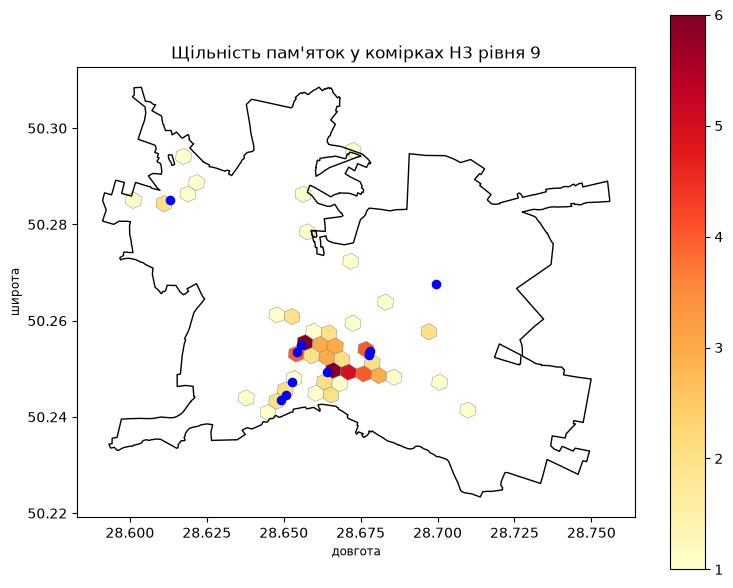

In [29]:
import h3
from shapely.geometry import Polygon

H3_RES = 9
print('середнє ребро комірки: %.0f м' % h3.average_hexagon_edge_length(H3_RES, unit='m'))

pts = cand.geometry.representative_point()
cand['h3'] = [h3.latlng_to_cell(p.y, p.x, H3_RES) for p in pts]
dens = cand['h3'].value_counts()

hexes = gpd.GeoDataFrame(
    {'h3': dens.index, 'count': dens.values},
    geometry=[Polygon([(lng, lat) for lat, lng in h3.cell_to_boundary(c)])
              for c in dens.index],
    crs='EPSG:4326')

share = dens.cumsum() / dens.sum()
cells_half = int((share < 0.5).sum()) + 1
print('непорожніх комірок:', len(dens))
print('половина пам\'яток зосереджена у %d комірках' % cells_half)

ax = hexes.plot(column='count', cmap='YlOrRd', legend=True, figsize=(9, 9),
                edgecolor='grey', linewidth=0.3)
boundary.boundary.plot(ax=ax, color='black', linewidth=1)
pts10.plot(ax=ax, color='blue', markersize=35, zorder=3)
ax.set_title('Щільність пам\'яток у комірках H3 рівня 9')
ax.set_xlabel('довгота')
ax.set_ylabel('широта')
plt.show()

> **Пастка.** `h3.cell_to_boundary` повертає пари **(lat, lng)**, а
> `shapely.Polygon` чекає **(x, y)**, тобто (lng, lat). Переплутаєте — місто
> опиниться в Індійському океані. Це видно одразу, тому дивіться на карту.

### Питання до звіту

У скількох комірках зосереджено половину всіх пам'яток вашого міста?
Що це говорить про форму маршруту?

---
## 8. Просторове поєднання

### Завдання 8.1

Для кожної точки маршруту знайдіть найближчий заклад із шару `amenities`
(`sjoin_nearest`) і виведіть таблицю з відстанню в метрах.

Нагадування: `sjoin_nearest` рахує в одиницях CRS. У градусах результат буде
безглуздим — перепроєктуйте обидва шари в метричну систему.

In [30]:
pts_m = pts10.to_crs(32635).reset_index(drop=True)
pts_m['point_id'] = pts_m.index

am_m = amenities.to_crs(32635)[['name', 'amenity', 'geometry']]

near = gpd.sjoin_nearest(pts_m, am_m, how='left', distance_col='distance_m',
                         lsuffix='point', rsuffix='place')
near = near.drop_duplicates('point_id').sort_values('point_id')

table = pd.DataFrame({
    'точка маршруту': near['name_point'],
    'заклад': near['name_place'].fillna('(без назви)'),
    'тип': near['amenity'],
    'відстань, м': near['distance_m'].round(0).astype(int)
}).reset_index(drop=True)

display(table)
print('медіана: %.0f м | максимум: %.0f м'
      % (table['відстань, м'].median(), table['відстань, м'].max()))

,точка маршруту,заклад,тип,"відстань, м"
0,СТАРТ: Житомир,Нептун,restaurant,499
1,Житомирський обласний краєзнавчий музей,Reikartz,restaurant,103
2,Музей космонавтики,№15 CoffeeTeaBoutique,cafe,286
3,Будинок-музей Корольова,№15 CoffeeTeaBoutique,cafe,319
4,Водонапірна вежа,Теретенія,cafe,11
5,1100 років Житомиру,"Ресторан ""Одеса»",restaurant,69
6,С.П. Корольов,№15 CoffeeTeaBoutique,cafe,289
7,Монумент Слави,Смачні українські страви. Караоке,cafe,552
8,Танк Т-34-85,Смачні українські страви. Караоке,cafe,633
9,МіГ-15УТИ,Портал,cafe,505


медіана: 319 м | максимум: 633 м


---
## 9. Маршрут на карті

Лінія маршруту — це **геометрія ребер графа**, а не відрізки між пам'ятками.

### Завдання 9.1

Побудуйте карту, на якій **обидві** лінії: справжній маршрут по ребрах і
прямі відрізки між точками. Різниця має бути видно оком.

In [31]:
node_xy = nodes.set_index('osmid')[['x', 'y']]

def route_coords(tour, ids):
    """Координати маршруту по ребрах графа у форматі (lat, lon) для folium."""
    coords = []
    for a, b in zip(tour[:-1], tour[1:]):
        try:
            path = nx.shortest_path(G, ids[a], ids[b], weight='length')
        except nx.NetworkXNoPath:
            path = [ids[a], ids[b]]
        for nd in path:
            coords.append((float(node_xy.loc[nd, 'y']), float(node_xy.loc[nd, 'x'])))
    return coords

road_line = route_coords(ex10, ids10)
straight_line = [(pts10.geometry.y.iloc[i], pts10.geometry.x.iloc[i]) for i in ex10]

fmap = folium.Map(location=road_line[0], zoom_start=14, tiles=BASEMAP)
folium.PolyLine(road_line, color='blue', weight=4,
                tooltip='маршрут по ребрах графа').add_to(fmap)
folium.PolyLine(straight_line, color='red', weight=2, dash_array='6',
                tooltip='прямі відрізки').add_to(fmap)
for step, i in enumerate(ex10[:-1]):
    lat, lon = pts10.geometry.y.iloc[i], pts10.geometry.x.iloc[i]
    folium.Marker([lat, lon], tooltip=str(pts10['name'].iloc[i]),
                  icon=folium.DivIcon(html=(
                      '<div style="width:22px;height:22px;border-radius:50%%;background:#fff;'
                      'border:2px solid #222;text-align:center;font:bold 12px/22px sans-serif">'
                      '%d</div>' % step))).add_to(fmap)
fmap.save('lr5_маршрут.html')
print('довжина по графу: %.2f км | сума прямих: %.2f км'
      % (L_opt / 1000, sum(E10[a, b] for a, b in zip(ex10[:-1], ex10[1:])) / 1000))
fmap

довжина по графу: 20.73 км | сума прямих: 16.91 км


---
## 10. Результати для лабораторної роботи № 8

Збережіть файл, який ЛР8 прочитає і спробує побити.

In [32]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'місто': CITY,
    'мала_задача': {
        'точок': len(ids10),
        'оптимум_м': round(L_opt, 1),
        'оптимальний_порядок': [str(pts10['name'].iloc[i]) for i in ex10],
        'найближчий_сусід_м': round(tour_length(D10, nn10), 1),
        'двоопт_м': round(tour_length(D10, op10), 1),
    },
    'велика_задача': {
        'точок': len(ids30),
        'найближчий_сусід_м': round(L_nn30, 1),
        'двоопт_м': round(L_op30, 1),
        'двоопт_с': round(t_op30, 4),
        'точки': [{'name': str(pts30['name'].iloc[i]),
                   'lat': float(pts30.geometry.y.iloc[i]),
                   'lon': float(pts30.geometry.x.iloc[i])} for i in range(len(pts30))],
        'матриця_віддалей_м': [[None if not np.isfinite(v) else round(float(v), 1)
                                for v in row] for row in D30],
    },
}
with open('lr5_результати.json', 'w', encoding='utf-8') as f:
    json.dump(result, f, ensure_ascii=False, indent=1)
print('збережено lr5_результати.json (%.1f КБ)' % (os.path.getsize('lr5_результати.json') / 1024))

збережено lr5_результати.json (16.7 КБ)


---
## 11. Звіт

Відповіді пишіть просто в наступній комірці, числами зі своїх обчислень.

1. **Скільки об'єктів ви відкинули** на кроці 2 і за яким правилом? Чи погодились
   би ви віддати цей фільтр замовнику без пояснень?
2. **Які сигнали ввійшли у ваш рейтинг і з якими вагами?** Чому саме так?
3. **Скільки об'єктів збіглося** у ваших двох рейтингах із десяти? Що це
   означає для слова «найкращі»?
4. **Який у вас коефіцієнт обходу** і чи типовий він? Якщо ні — що в місті
   його пояснює?
5. **На скільки відсотків** найближчий сусід гірший за точний розв'язок?
   Чи здивувало вас це число?
6. **Чому точний розв'язок на 30 точках недоступний?** Назвіть конкретну
   величину, яка цьому заважає.
7. **Що у ваших даних виявилось неправильним** — дублікати, пропущені назви,
   об'єкти не на місці? Як ви з цим вчинили?

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-помічником, у яких саме місцях і як перевіряли
отриманий код. Використання дозволене; **неперевірене** використання — ні.

In [33]:
L_nn10 = tour_length(D10, nn10)
L_op10 = tour_length(D10, op10)
snapshot_s = sum(v['секунд'] for v in COST.values())
snapshot_mb = sum(v['файл_МБ'] for v in COST.values())
n_heritage, n_noname = len(heritage), int((~has_name).sum())
detour10 = detour_factor(D10, E10)
typical = ('типовий для пішохідної мережі міста (1,2-1,6)' if 1.2 <= detour10 <= 1.6
           else 'поза типовим діапазоном 1,2-1,6, це треба пояснити особливостями міста')
glued10 = len(ids10) - len(np.unique(ids10))
glued30 = len(ids30) - len(np.unique(ids30))
glue_text = ('Після очищення злиплих точок немає.' if glued10 == 0 and glued30 == 0
             else 'Після очищення злиплих точок лишилось: %d у малій і %d у великій задачі.'
                  % (glued10, glued30))
half_share = 100 * cells_half / len(dens)
hx_gb = 2 ** 30 * 30 * 8 / 1e9

REPORT = f'''
Завдання 1.2. Живий запит Overpass не пройшов: сервер відхилив запит, а дзеркала дали таймаут або 502.
Дані взято з файлу Geofabrik для України: 883 МБ мережею, завантаження близько 2 хв, перший прохід обробки близько 8,4 хв
(час другого проходу не зафіксовано). Читання всього знімка: {snapshot_s:.2f} с, 0 МБ мережею, файли {snapshot_mb:.2f} МБ.
При повторному запуску мережею не передано 883 МБ. Лише завантаження (120 с) повільніше за знімок приблизно в {120 / snapshot_s:.0f} разів. Це порівняння з Geofabrik, а не з Overpass.

1. У шарі heritage {n_heritage} об'єктів, за тегами підійшли всі, бо шар завантажено за цими самими тегами. Відкинуто {n_noname} без тега name.
Без пояснень замовнику фільтр не віддав би: він прибирає й реальні, але не підписані пам'ятки. Ще {n_removed} записів видалено на кроці 3.3.

2. Сигнали й ваги: wiki 0,40 (об'єкт описали сторонні люди), кількість мов назви 0,30 (ширший інтерес), музей або галерея 0,15
(призначені для відвідування), historic 0,10 (широкий тег), площа 0,05 (найслабший сигнал). Кількість мов і площу зведено через rank(pct=True).
Ваги є обґрунтованим експертним рішенням, а не об'єктивною істиною.

3. Після очищення в перших десяти збіглось {overlap} із {N_SMALL} об'єктів. Обидва списки правильні, але відповідають на різні запитання,
тому значення слова «найкращі» задає критерій, а не дані.

4. Коефіцієнт обходу {detour10:.2f}, {typical}. Асиметрія {float(np.max(np.abs(D10 - D10.T))):.0f} м, бо в пішохідній мережі кожне ребро додано в обидва боки.

5. Найближчий сусід гірший за точний розв'язок на {100 * (L_nn10 / L_opt - 1):.2f}% ({L_nn10:.0f} м проти {L_opt:.0f} м), 2-opt на {100 * (L_op10 / L_opt - 1):.2f}%.
Для жадібного методу такий розрив очікуваний: наприкінці він робить довгі переходи, які 2-opt частково виправляє.
На 30 точках 2-opt скорочує маршрут на {100 * (1 - L_op30 / L_nn30):.1f}% порівняно з найближчим сусідом.

6. Заважає обсяг пам'яті: для 31 точки таблиця Held-Karp має 2^30 * 30 = 32,2 млрд клітин, тобто близько {hx_gb:.0f} ГБ при 8 байтах на клітину.
Реалізація ще зберігає другу таблицю такого самого розміру для відновлення маршруту.

7. Проблеми в даних: запит міста повернув область площею 29825,7 км² замість міста 60,4 км², тому запит уточнено.
Об'єкти дублювались: Музей космонавтики й Водонапірна вежа були двічі, тому зайві записи видалено. Ракети Р-12 і Р-5В стоять за 18-23 м від Музею космонавтики, тому я вважаю їх його експонатами й теж видалив. Інші об'єкти ближче 60 м лишено як окремі пам'ятки.
{glue_text} Однакові назви далі 60 м: {same_name_left if same_name_left else 'немає'}. Відношення OSM не враховані, тому частина великих об'єктів може бути відсутня.

H3. Половина пам'яток зосереджена в {cells_half} із {len(dens)} непорожніх комірок ({half_share:.0f}%). Отже, маршрут має щільні ділянки в місцях скупчення,
а довжину здебільшого дають переходи між ними й до віддалених об'єктів.

Висновок поза завданням: помилки цієї роботи не викликали повідомлень про помилку. Область замість міста й дублікати виявились лише через перевірку чисел, тому такі перевірки потрібні не менше за сам алгоритм.

Декларація про використання ШІ: використано ШІ-помічника Claude для написання та пояснення коду завдань, заміни джерела даних і чернетки цього звіту.
Код перевірено запуском ноутбука, перевірками check_snap і check_tour, твердженнями assert та контрольними ознаками із завдання.
'''
print(REPORT)


Завдання 1.2. Живий запит Overpass не пройшов: сервер відхилив запит, а дзеркала дали таймаут або 502.
Дані взято з файлу Geofabrik для України: 883 МБ мережею, завантаження близько 2 хв, перший прохід обробки близько 8,4 хв
(час другого проходу не зафіксовано). Читання всього знімка: 0.36 с, 0 МБ мережею, файли 3.25 МБ.
При повторному запуску мережею не передано 883 МБ. Лише завантаження (120 с) повільніше за знімок приблизно в 335 разів. Це порівняння з Geofabrik, а не з Overpass.

1. У шарі heritage 108 об'єктів, за тегами підійшли всі, бо шар завантажено за цими самими тегами. Відкинуто 19 без тега name.
Без пояснень замовнику фільтр не віддав би: він прибирає й реальні, але не підписані пам'ятки. Ще 6 записів видалено на кроці 3.3.

2. Сигнали й ваги: wiki 0,40 (об'єкт описали сторонні люди), кількість мов назви 0,30 (ширший інтерес), музей або галерея 0,15
(призначені для відвідування), historic 0,10 (широкий тег), площа 0,05 (найслабший сигнал). Кількість мов і площу зведено че